# 01 — EDA y calidad de datos | Credit Risk Scoring

**Objetivo:** analizar el dataset *Default of Credit Card Clients* (UCI ID 350) antes de modelar la probabilidad de incumplimiento del mes siguiente.

**Fuente:** [UCI](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients) · [DOI](https://doi.org/10.24432/C55S3H) · Yeh (2009), licencia CC BY 4.0. 30,000 clientes, 23 predictores. Datos de Taiwán, abril–septiembre de 2005; importes en TWD.

**Nota:** ejemplo educativo, no válido para decisiones de crédito reales sin validación adicional de población, temporalidad, equidad, calibración y gobernanza.

## 1. Preparación del entorno
Instala las dependencias con `pip install -r requirements.txt` desde la raíz del repositorio, o ejecuta la siguiente celda si aún no están instaladas:

In [1]:
%pip install -q pandas numpy matplotlib seaborn ucimlrepo openpyxl

Note: you may need to restart the kernel to use updated packages.


### Importaciones y rutas
El notebook funciona tanto desde la carpeta `notebooks/` como desde la raíz del proyecto.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.3f}".format)
RANDOM_STATE = 42
ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
for directory in (RAW, PROCESSED, FIGURES):
    directory.mkdir(parents=True, exist_ok=True)
print("Raíz del proyecto:", ROOT.resolve())

Raíz del proyecto: C:\Users\pirom\OneDrive\Documentos\Proyectos\Credit Risk Scoring & Default Prediction


## 2. Descarga y lectura del dataset
Se descarga automáticamente desde UCI en la primera ejecución, y se guarda una copia CSV para ejecuciones posteriores sin conexión. Si la descarga está bloqueada, descarga el `.xls` desde el sitio de UCI y colócalo en `data/raw/`.

In [3]:
csv_path = RAW / "default_credit_clients.csv"
if csv_path.exists():
    df = pd.read_csv(csv_path)
    print("Datos cargados desde caché:", csv_path)
else:
    xls_files = list(RAW.glob("*.xls"))
    if xls_files:
        df = pd.read_excel(xls_files[0], header=1)
        print("Datos cargados desde archivo XLS:", xls_files[0])
    else:
        try:
            from ucimlrepo import fetch_ucirepo
            dataset = fetch_ucirepo(id=350)
            df = pd.concat([dataset.data.features, dataset.data.targets], axis=1)
            print("Datos descargados de UCI (ID 350)")
        except Exception as exc:
            raise RuntimeError("No se pudieron descargar los datos. Revisa internet o guarda el XLS de UCI en data/raw/.") from exc
    df.to_csv(csv_path, index=False)

# Unificar nombres porque algunos mirrors o versiones utilizan variantes.
df.columns = df.columns.astype(str).str.strip()
if "default payment next month" in df.columns:
    df = df.rename(columns={"default payment next month": "default.payment.next.month"})
if "Y" in df.columns and "default.payment.next.month" not in df.columns:
    df = df.rename(columns={"Y": "default.payment.next.month"})
TARGET = "default.payment.next.month"
assert TARGET in df.columns, f"Falta target. Columnas disponibles: {list(df.columns)}"
assert df.shape[0] == 30000, f"Se esperaban 30,000 registros, llegaron {len(df)}"
assert set(df[TARGET].dropna().unique()).issubset({0, 1}), "Target debe ser binario"
print("Dimensiones:", df.shape)
display(df.head())

Datos cargados desde caché: C:\Users\pirom\OneDrive\Documentos\Proyectos\Credit Risk Scoring & Default Prediction\data\raw\default_credit_clients.csv
Dimensiones: (30000, 24)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,X21,X22,X23,default.payment.next.month
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 3. Diccionario de variables
La tabla identifica el significado de cada bloque. `PAY_0` es septiembre, `PAY_2` agosto; no hay `PAY_1`. Los códigos -2 y 0 en los historiales deben revisarse antes de interpretarlos como meses de atraso; no se recodifican automáticamente.

In [4]:
definitions = {
    "ID": "Identificador del registro (no usar para entrenar)",
    "LIMIT_BAL": "Límite de crédito otorgado, TWD",
    "SEX": "Sexo registrado: 1=masculino, 2=femenino (atributo sensible)",
    "EDUCATION": "Educación: 1=posgrado, 2=universidad, 3=bachillerato, 4=otros; otros códigos requieren revisión",
    "MARRIAGE": "Estado civil: 1=casado, 2=soltero, 3=otros; código 0 requiere revisión",
    "AGE": "Edad en años",
    **{p: f"Estado de pago: {month} de 2005; -1=al día, 1..9=meses de demora; otros códigos requieren revisión" for p,month in zip(["PAY_0","PAY_2","PAY_3","PAY_4","PAY_5","PAY_6"],["septiembre","agosto","julio","junio","mayo","abril"])},
    **{f"BILL_AMT{i}": f"Importe facturado del periodo {i}, TWD" for i in range(1,7)},
    **{f"PAY_AMT{i}": f"Pago realizado en el periodo {i}, TWD" for i in range(1,7)},
    TARGET: "Incumplimiento al mes siguiente: 1=sí, 0=no"
}
data_dictionary = pd.DataFrame({"variable":df.columns, "descripcion":[definitions.get(col,"Verificar con fuente") for col in df.columns], "tipo":[str(t) for t in df.dtypes]})
display(data_dictionary)
data_dictionary.to_csv(PROCESSED / "data_dictionary.csv", index=False)

,variable,descripcion,tipo
0,X1,Verificar con fuente,int64
1,X2,Verificar con fuente,int64
2,X3,Verificar con fuente,int64
3,X4,Verificar con fuente,int64
4,X5,Verificar con fuente,int64
5,X6,Verificar con fuente,int64
6,X7,Verificar con fuente,int64
7,X8,Verificar con fuente,int64
8,X9,Verificar con fuente,int64
9,X10,Verificar con fuente,int64


## 4. Calidad de datos
Vamos a comprobar nulos, duplicados, unicidad de ID, categorías no documentadas, tipos y rangos. No modificamos aún registros sospechosos: primero los documentamos.

In [5]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_n": df.isna().sum(),
    "missing_pct": df.isna().mean()*100,
    "unique_n": df.nunique(dropna=False),
}).sort_values(["missing_pct","unique_n"], ascending=[False,True])
display(quality)
print("Filas duplicadas:", int(df.duplicated().sum()))
if "ID" in df.columns:
    print("IDs duplicados:", int(df["ID"].duplicated().sum()))
print("Valores del target:", sorted(df[TARGET].dropna().unique().tolist()))
print("Columnas faltantes respecto del diccionario:", sorted(set(definitions) - set(df.columns)))

,dtype,missing_n,missing_pct,unique_n
X2,int64,0,0.000,2
default.payment.next.month,int64,0,0.000,2
X4,int64,0,0.000,4
X3,int64,0,0.000,7
X10,int64,0,0.000,10
X11,int64,0,0.000,10
X6,int64,0,0.000,11
X7,int64,0,0.000,11
X8,int64,0,0.000,11
X9,int64,0,0.000,11


Filas duplicadas: 35
Valores del target: [0, 1]
Columnas faltantes respecto del diccionario: ['AGE', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'EDUCATION', 'ID', 'LIMIT_BAL', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'SEX']


In [6]:
categorical = [col for col in ["SEX", "EDUCATION", "MARRIAGE"] if col in df]
status_cols = [col for col in ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"] if col in df]
for col in categorical + status_cols:
    print(f"\n{col}: {df[col].value_counts(dropna=False).sort_index().to_dict()}")

invalid = {}
for col,valid in {"SEX":{1,2},"EDUCATION":{1,2,3,4},"MARRIAGE":{1,2,3}}.items():
    if col in df:
        invalid[col] = int((~df[col].isin(valid)).sum())
if "LIMIT_BAL" in df: invalid["LIMIT_BAL<=0"] = int((df["LIMIT_BAL"]<=0).sum())
if "AGE" in df: invalid["AGE fuera de 18..100"] = int((~df["AGE"].between(18,100)).sum())
for col in status_cols: invalid[f"{col} fuera de -1..9"] = int((~df[col].between(-1,9)).sum())
flags = pd.DataFrame(invalid.items(), columns=["regla", "n_registros"])
display(flags.sort_values("n_registros", ascending=False))
flags.to_csv(PROCESSED / "quality_flags.csv", index=False)
print("Nota: los negativos en BILL_AMT pueden ser saldos a favor, no necesariamente errores.")

,regla,n_registros


Nota: los negativos en BILL_AMT pueden ser saldos a favor, no necesariamente errores.


## 5. EDA: variable objetivo
Calculamos la prevalencia histórica del incumplimiento: servirá como línea base en las fases de modelado.

In [7]:
target_counts = df[TARGET].value_counts().sort_index()
target_rates = (df[TARGET].value_counts(normalize=True).sort_index()*100)
display(pd.DataFrame({"clientes":target_counts,"porcentaje":target_rates.round(2)}))
print(f"Tasa de incumplimiento: {df[TARGET].mean():.2%}")
fig,ax=plt.subplots(figsize=(7,4))
labels=["No incumple (0)","Incumple (1)"]
ax.bar(labels,[target_counts.get(0,0),target_counts.get(1,0)])
ax.set(title="Distribución del incumplimiento",ylabel="Número de clientes")
for index, count in enumerate([target_counts.get(0,0),target_counts.get(1,0)]):
    ax.text(index,count+150,f"{count:,}",ha="center")
plt.tight_layout();plt.savefig(FIGURES / "target_distribution.png",dpi=150);plt.show()

,clientes,porcentaje
default.payment.next.month,,
0,23364,77.880
1,6636,22.120


Tasa de incumplimiento: 22.12%


<Figure size 700x400 with 1 Axes>

In [8]:
# Diccionario de variables del dataset UCI
column_mapping = {
    "X1": "LIMIT_BAL",
    "X2": "SEX",
    "X3": "EDUCATION",
    "X4": "MARRIAGE",
    "X5": "AGE",
    "X6": "PAY_0",
    "X7": "PAY_2",
    "X8": "PAY_3",
    "X9": "PAY_4",
    "X10": "PAY_5",
    "X11": "PAY_6",
    "X12": "BILL_AMT1",
    "X13": "BILL_AMT2",
    "X14": "BILL_AMT3",
    "X15": "BILL_AMT4",
    "X16": "BILL_AMT5",
    "X17": "BILL_AMT6",
    "X18": "PAY_AMT1",
    "X19": "PAY_AMT2",
    "X20": "PAY_AMT3",
    "X21": "PAY_AMT4",
    "X22": "PAY_AMT5",
    "X23": "PAY_AMT6",
    "default.payment.next.month": "DEFAULT"
}

df = df.rename(columns=column_mapping)

print("Dimensiones:", df.shape)
print("\nColumnas renombradas:")
print(df.columns.tolist())

display(df.head())

Dimensiones: (30000, 24)

Columnas renombradas:
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'DEFAULT']


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


## 6. EDA: variables numéricas
La mediana y percentiles son más informativos que la media cuando existen colas largas.

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
LIMIT_BAL,"30,000.000","167,484.323","129,747.662","10,000.000","10,000.000","50,000.000","140,000.000","240,000.000","430,000.000","500,000.000","1,000,000.000"
AGE,"30,000.000",35.486,9.218,21.000,22.000,28.000,34.000,41.000,53.000,60.000,79.000
BILL_AMT1,"30,000.000","51,223.331","73,635.861","-165,580.000",-81.000,"3,558.750","22,381.500","67,091.000","201,203.050","350,110.680","964,511.000"
PAY_AMT1,"30,000.000","5,663.581","16,563.280",0.000,0.000,"1,000.000","2,100.000","5,006.000","18,428.200","66,522.180","873,552.000"


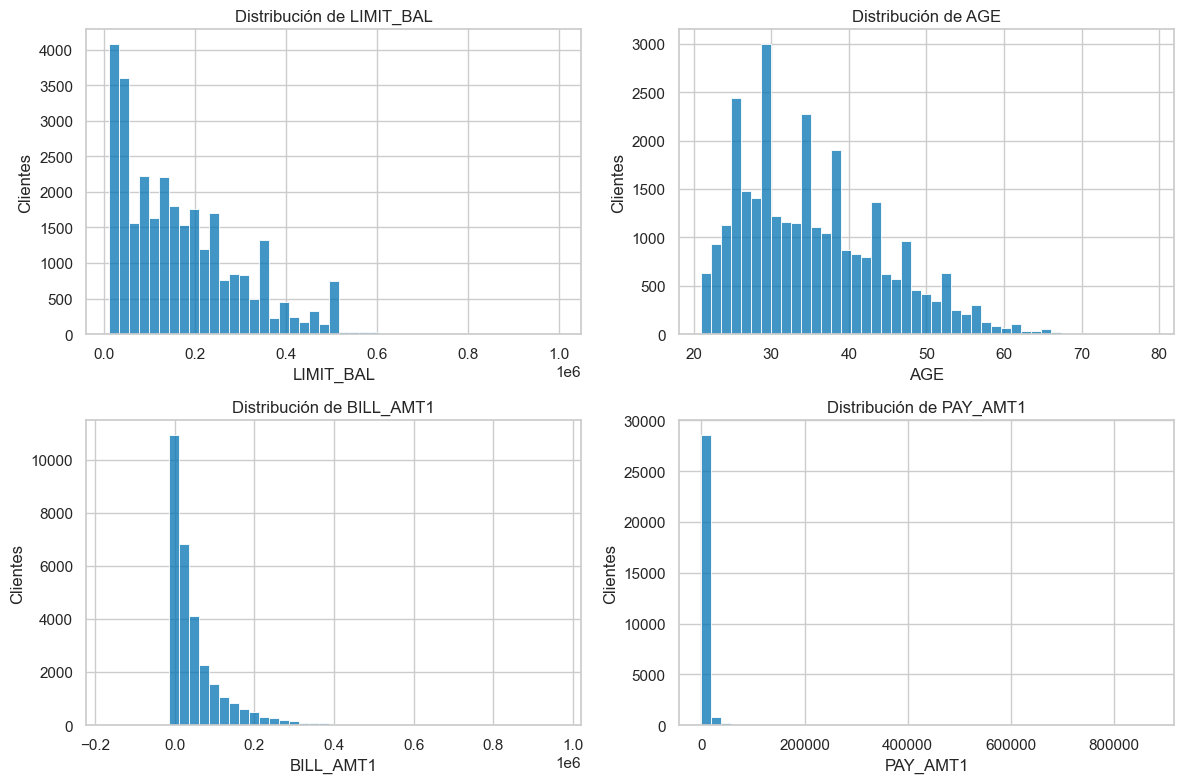

In [9]:
numeric_cols=[col for col in ["LIMIT_BAL","AGE","BILL_AMT1","PAY_AMT1"] if col in df]
display(df[numeric_cols].describe(percentiles=[.01,.25,.5,.75,.95,.99]).T)
fig, axes=plt.subplots(2,2,figsize=(12,8))
for col,ax in zip(numeric_cols,axes.flat):
    sns.histplot(df[col],bins=45,ax=ax)
    ax.set(title=f"Distribución de {col}",xlabel=col,ylabel="Clientes")
for ax in axes.flat[len(numeric_cols):]:ax.set_visible(False)
plt.tight_layout();plt.savefig(FIGURES / "numeric_distributions.png",dpi=150);plt.show()

## 7. EDA bivariado: riesgo según historial de pago
Representamos la tasa histórica de incumplimiento por `PAY_0`. **Asociación no implica causalidad.** Los códigos -2 y 0 se muestran sin imponer una interpretación.

,PAY_0,clientes,tasa_default,tasa_default_pct
0,-2,2759,0.132,13.229
1,-1,5686,0.168,16.778
2,0,14737,0.128,12.811
3,1,3688,0.339,33.948
4,2,2667,0.691,69.141
5,3,322,0.758,75.776
6,4,76,0.684,68.421
7,5,26,0.500,50.000
8,6,11,0.545,54.545
9,7,9,0.778,77.778


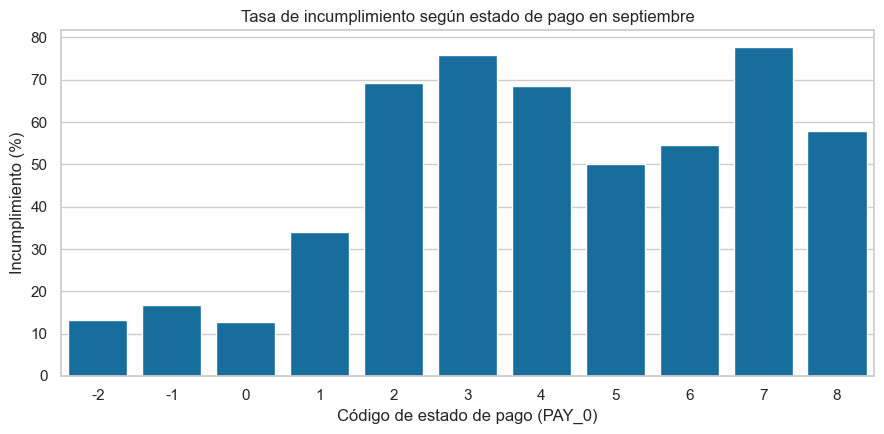

In [11]:
TARGET = "DEFAULT"
risk_by_status=(df.groupby("PAY_0",dropna=False)[TARGET].agg(clientes="size",tasa_default="mean")
                .reset_index().sort_values("PAY_0"))
risk_by_status["tasa_default_pct"]=risk_by_status["tasa_default"]*100
display(risk_by_status)
fig,ax=plt.subplots(figsize=(9,4.5))
sns.barplot(data=risk_by_status,x="PAY_0",y="tasa_default_pct",ax=ax)
ax.set(title="Tasa de incumplimiento según estado de pago en septiembre",xlabel="Código de estado de pago (PAY_0)",ylabel="Incumplimiento (%)")
plt.tight_layout();plt.savefig(FIGURES / "default_by_payment_status.png",dpi=150);plt.show()

## 8. EDA bivariado: límite de crédito y edad
Los deciles son descriptivos, calculados con todos los registros; para construir features predictivas después aplicaremos transformaciones ajustadas solo al train.

,clientes,tasa_default,tasa_default_pct
segmento,,,
"(9999.999, 30000.0]",4081,0.358,35.849
"(30000.0, 50000.0]",3595,0.272,27.177
"(50000.0, 70000.0]",1556,0.285,28.470
"(70000.0, 100000.0]",3266,0.245,24.525
"(100000.0, 140000.0]",2792,0.229,22.851
"(140000.0, 180000.0]",3331,0.174,17.352
"(180000.0, 210000.0]",2487,0.175,17.531
"(210000.0, 270000.0]",2934,0.163,16.292
"(270000.0, 360000.0]",3482,0.152,15.164


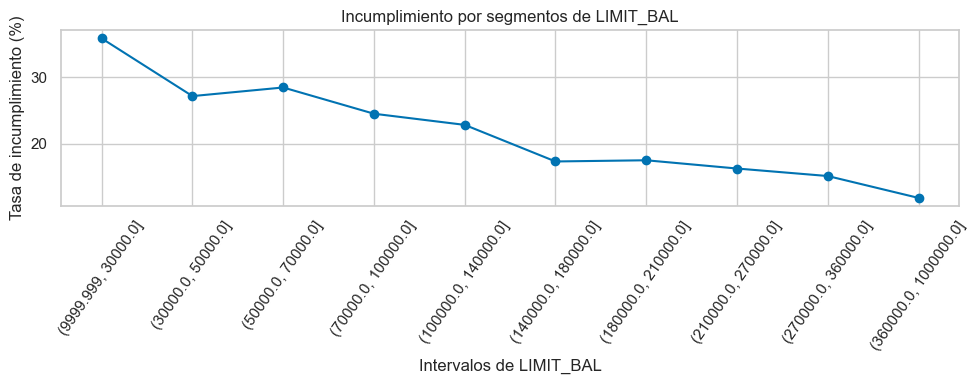

,clientes,tasa_default,tasa_default_pct
segmento,,,
"(20.999, 25.0]",3871,0.267,26.660
"(25.0, 27.0]",2733,0.207,20.710
"(27.0, 29.0]",3014,0.199,19.874
"(29.0, 31.0]",2612,0.193,19.257
"(31.0, 34.0]",3466,0.194,19.359
"(34.0, 37.0]",3262,0.217,21.735
"(37.0, 40.0]",2768,0.210,20.954
"(40.0, 43.0]",2288,0.227,22.727
"(43.0, 49.0]",3306,0.235,23.533


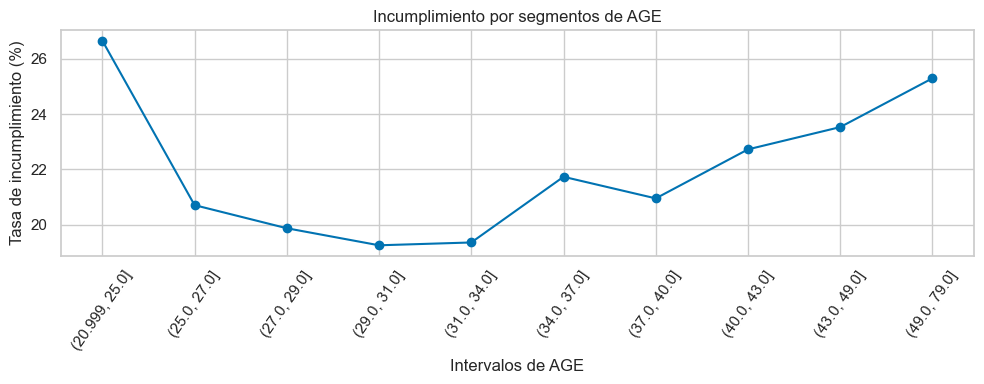

In [12]:
for col in ["LIMIT_BAL","AGE"]:
    tmp=df[[col,TARGET]].copy()
    tmp["segmento"]=pd.qcut(tmp[col],q=10,duplicates="drop")
    result=tmp.groupby("segmento",observed=True)[TARGET].agg(clientes="size",tasa_default="mean")
    result["tasa_default_pct"]=result["tasa_default"]*100
    display(result)
    fig,ax=plt.subplots(figsize=(10,4))
    ax.plot(range(len(result)),result["tasa_default_pct"],marker="o")
    ax.set(xticks=range(len(result)),xticklabels=[str(x) for x in result.index],xlabel=f"Intervalos de {col}",ylabel="Tasa de incumplimiento (%)",title=f"Incumplimiento por segmentos de {col}")
    ax.tick_params(axis="x",rotation=55)
    plt.tight_layout();plt.savefig(FIGURES / f"default_by_{col.lower()}.png",dpi=150);plt.show()

## 9. Correlaciones exploratorias
Pearson sirve como primera aproximación numérica, pero **no** sustituye métricas de asociación apropiadas para variables categóricas ni evalúa efectos no lineales.

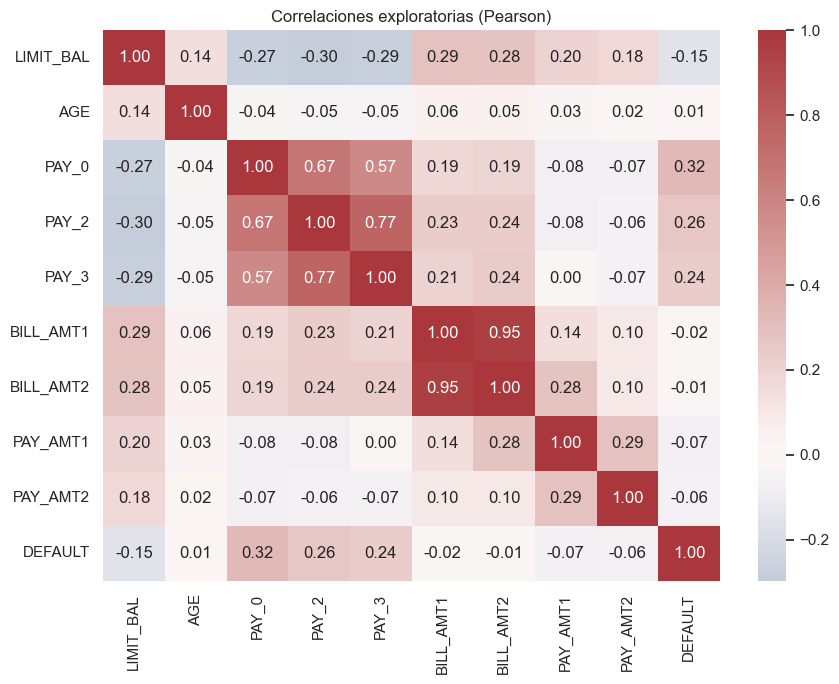

In [13]:
predictors = [c for c in ["LIMIT_BAL","AGE","PAY_0","PAY_2","PAY_3","BILL_AMT1","BILL_AMT2","PAY_AMT1","PAY_AMT2"] if c in df]
corr=df[predictors+[TARGET]].corr(numeric_only=True)
fig,ax=plt.subplots(figsize=(9,7))
sns.heatmap(corr,annot=True,fmt=".2f",cmap="vlag",center=0,ax=ax)
ax.set(title="Correlaciones exploratorias (Pearson)")
plt.tight_layout();plt.savefig(FIGURES / "correlation_heatmap.png",dpi=150);plt.show()

## 10. Verificación final y datos procesados
Guardamos una copia **sin transformaciones de modelado**, eliminando únicamente `ID` para preparar análisis posteriores. El original permanece intacto en `data/raw`.

In [14]:
assert df[TARGET].notna().all(), "El target contiene nulos"
assert len(df) == target_counts.sum(), "No coincide el conteo del target"
assert df[TARGET].between(0,1).all(), "Target inválido"
df_analysis=df.drop(columns=["ID"],errors="ignore").copy()
out=PROCESSED / "credit_risk_eda_base.csv"
df_analysis.to_csv(out,index=False)
print("Archivo generado:",out)
print("Dimensiones finales:",df_analysis.shape)
print("Tasa histórica:",round(100*df_analysis[TARGET].mean(),2),"%")

Archivo generado: C:\Users\pirom\OneDrive\Documentos\Proyectos\Credit Risk Scoring & Default Prediction\data\processed\credit_risk_eda_base.csv
Dimensiones finales: (30000, 24)
Tasa histórica: 22.12 %
